In [1]:
%pip install flask flask-cors pandas numpy scikit-learn xgboost shap joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import flask
import sqlite3
import pandas as pd
import numpy as np
import joblib

print("Backend environment ready!")
print("Flask version:", flask.__version__)
print("SQLite version:", sqlite3.sqlite_version)

Backend environment ready!
Flask version: 3.1.3
SQLite version: 3.53.2


C:\Users\Shashank\AppData\Local\Temp\ipykernel_10840\624861458.py:8: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask version:", flask.__version__)


In [3]:
import os

folders = [
    "../app",
    "../database",
    "../reports",
    "../models"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Backend folder structure created!")

Backend folder structure created!


In [4]:
import sqlite3

DB_PATH = "../database/predictive_maintenance.db"

connection = sqlite3.connect(DB_PATH)

print("Database connected successfully!")

Database connected successfully!


In [5]:
cursor = connection.cursor()

# TABLE 1: MACHINES

cursor.execute("""
CREATE TABLE IF NOT EXISTS machines (
    machine_id INTEGER PRIMARY KEY AUTOINCREMENT,
    machine_name TEXT NOT NULL UNIQUE,
    machine_type TEXT NOT NULL,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
)
""")

# TABLE 2: SENSOR READINGS

cursor.execute("""
CREATE TABLE IF NOT EXISTS sensor_readings (
    reading_id INTEGER PRIMARY KEY AUTOINCREMENT,
    machine_id INTEGER NOT NULL,
    air_temperature REAL NOT NULL,
    process_temperature REAL NOT NULL,
    rotational_speed REAL NOT NULL,
    torque REAL NOT NULL,
    tool_wear REAL NOT NULL,
    recorded_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
    FOREIGN KEY (machine_id) REFERENCES machines(machine_id)
)
""")

# TABLE 3: PREDICTIONS

cursor.execute("""
CREATE TABLE IF NOT EXISTS predictions (
    prediction_id INTEGER PRIMARY KEY AUTOINCREMENT,
    machine_id INTEGER NOT NULL,
    failure_probability REAL NOT NULL,
    machine_status TEXT NOT NULL,
    risk_level TEXT NOT NULL,
    recommendations TEXT,
    predicted_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
    FOREIGN KEY (machine_id) REFERENCES machines(machine_id)
)
""")

connection.commit()

print("All three database tables created successfully!")

All three database tables created successfully!


In [6]:
cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table'
""")

tables = cursor.fetchall()

print("Tables available in database:")

for table in tables:
    print(table[0])

Tables available in database:
machines
sqlite_sequence
sensor_readings
predictions


In [7]:
connection = sqlite3.connect(DB_PATH)

cursor = connection.cursor()

machines = [
    ("Machine A", "L"),
    ("Machine B", "M")
]

cursor.executemany("""
INSERT OR IGNORE INTO machines
(machine_name, machine_type)
VALUES (?, ?)
""", machines)

connection.commit()

print("Machines registered successfully!")

connection.close()

Machines registered successfully!


In [8]:
connection = sqlite3.connect(DB_PATH)

machines_df = pd.read_sql_query(
    "SELECT * FROM machines",
    connection
)

display(machines_df)

connection.close()

,machine_id,machine_name,machine_type,created_at
0,1,Machine A,L,2026-11-09 11:05:30
1,2,Machine B,M,2026-11-09 11:05:30


In [9]:
def save_sensor_reading(
    machine_id,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
):

    connection = sqlite3.connect(DB_PATH)
    cursor = connection.cursor()

    cursor.execute("""
        INSERT INTO sensor_readings (
            machine_id,
            air_temperature,
            process_temperature,
            rotational_speed,
            torque,
            tool_wear
        )
        VALUES (?, ?, ?, ?, ?, ?)
    """, (
        machine_id,
        air_temperature,
        process_temperature,
        rotational_speed,
        torque,
        tool_wear
    ))

    connection.commit()
    connection.close()

    print(f"Sensor readings saved for Machine ID {machine_id}!")

In [10]:
save_sensor_reading(
    machine_id=1,
    air_temperature=300.1,
    process_temperature=310.2,
    rotational_speed=1500,
    torque=40,
    tool_wear=50
)

save_sensor_reading(
    machine_id=2,
    air_temperature=302.0,
    process_temperature=311.0,
    rotational_speed=1400,
    torque=55,
    tool_wear=220
)

Sensor readings saved for Machine ID 1!
Sensor readings saved for Machine ID 2!


In [11]:
connection = sqlite3.connect(DB_PATH)

sensor_df = pd.read_sql_query("""
    SELECT
        m.machine_name,
        s.air_temperature,
        s.process_temperature,
        s.rotational_speed,
        s.torque,
        s.tool_wear,
        s.recorded_at
    FROM sensor_readings s
    JOIN machines m
    ON s.machine_id = m.machine_id
""", connection)

display(sensor_df)

connection.close()

,machine_name,air_temperature,process_temperature,rotational_speed,torque,tool_wear,recorded_at
0,Machine A,300.1,310.2,1500.0,40.0,50.0,2026-11-09 11:06:20
1,Machine B,302.0,311.0,1400.0,55.0,220.0,2026-11-09 11:06:20


In [12]:
def save_prediction(
    machine_id,
    result,
    maintenance
):

    connection = sqlite3.connect(DB_PATH)
    cursor = connection.cursor()

    cursor.execute("""
        INSERT INTO predictions (
            machine_id,
            failure_probability,
            machine_status,
            risk_level,
            recommendations
        )
        VALUES (?, ?, ?, ?, ?)
    """, (
        machine_id,
        result["failure_probability"],
        result["machine_status"],
        maintenance["risk_level"],
        " | ".join(maintenance["recommendations"])
    ))

    connection.commit()
    connection.close()

    print(f"Prediction saved for Machine ID {machine_id}!")

In [13]:
def analyze_and_save_machine(machine):

    # Generate prediction
    result = predict_machine_failure(
        air_temperature=machine["air_temperature"],
        process_temperature=machine["process_temperature"],
        rotational_speed=machine["rotational_speed"],
        torque=machine["torque"],
        tool_wear=machine["tool_wear"],
        machine_type=machine["machine_type"]
    )

    # Generate maintenance recommendations
    maintenance = generate_maintenance_recommendation(
        result=result,
        tool_wear=machine["tool_wear"],
        torque=machine["torque"],
        rotational_speed=machine["rotational_speed"],
        temperature_difference=(
            machine["process_temperature"]
            - machine["air_temperature"]
        )
    )

    # Save prediction
    save_prediction(
        machine_id=machine["machine_id"],
        result=result,
        maintenance=maintenance
    )

    return result, maintenance

In [15]:
def predict_machine_failure(
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear,
    machine_type
):

    # Validate inputs
    if machine_type not in ["L", "M", "H"]:
        raise ValueError("Machine type must be L, M or H.")

    if air_temperature <= 0 or process_temperature <= 0:
        raise ValueError("Temperatures must be positive.")

    if rotational_speed <= 0 or torque < 0 or tool_wear < 0:
        raise ValueError("Invalid sensor values.")

    # Feature engineering
    temperature_difference = process_temperature - air_temperature

    mechanical_power = (
        torque * rotational_speed * (2 * np.pi / 60)
    ) / 1000

    # Raw model features
    machine_data = pd.DataFrame([{
        "Air temperature [K]": air_temperature,
        "Process temperature [K]": process_temperature,
        "Rotational speed [rpm]": rotational_speed,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear,
        "Temperature Difference [K]": temperature_difference,
        "Mechanical Power [kW]": mechanical_power,
        "Type": machine_type
    }])

    # Preprocessing
    processed_data = preprocessor.transform(machine_data)

    processed_data = pd.DataFrame(
        processed_data,
        columns=model.get_booster().feature_names
    )

    # Prediction
    probability = model.predict_proba(processed_data)[0][1]

    prediction = int(probability >= threshold)

    return {
        "failure_probability": round(float(probability) * 100, 2),
        "prediction": prediction,
        "machine_status": "FAILURE RISK" if prediction == 1 else "NORMAL",
        "temperature_difference": round(temperature_difference, 2),
        "mechanical_power": round(mechanical_power, 2),
        "machine_type": machine_type
    }

print("Prediction function is ready!")

Prediction function is ready!


In [16]:
def generate_maintenance_recommendation(
    result,
    tool_wear,
    torque,
    rotational_speed,
    temperature_difference
):

    recommendations = []

    risk = classify_risk(result["failure_probability"])

    if risk == "HIGH":
        recommendations.append(
            "High failure risk: Arrange prompt machine inspection."
        )

    elif risk == "MEDIUM":
        recommendations.append(
            "Moderate failure risk: Schedule a maintenance inspection."
        )

    else:
        recommendations.append(
            "Low failure risk: Continue routine monitoring."
        )

    if tool_wear >= 200:
        recommendations.append(
            "High tool wear: Inspect cutting tool and assess replacement."
        )

    if torque >= 55:
        recommendations.append(
            "Elevated torque: Inspect mechanical load and drive components."
        )

    if rotational_speed <= 1300:
        recommendations.append(
            "Low rotational speed: Inspect motor and operating conditions."
        )

    if temperature_difference <= 8:
        recommendations.append(
            "Low temperature difference: Verify operating temperature sensors."
        )

    return {
        "risk_level": risk,
        "recommendations": recommendations
    }

print("Recommendation function is ready!")

Recommendation function is ready!


In [17]:
for machine in database_test_machines:

    result, maintenance = analyze_and_save_machine(machine)

    print("\nMachine ID:", machine["machine_id"])
    print("Failure Probability:", result["failure_probability"], "%")
    print("Risk Level:", maintenance["risk_level"])

NameError: name 'preprocessor' is not defined

In [18]:
import joblib

preprocessor = joblib.load(
    "../models/preprocessor_fe.pkl"
)

print("Preprocessor loaded successfully!")

Preprocessor loaded successfully!


In [19]:
print("Model loaded:", model is not None)
print("Preprocessor loaded:", preprocessor is not None)
print("Threshold:", threshold)

print("Prediction function:", callable(predict_machine_failure))
print("Recommendation function:",
      callable(generate_maintenance_recommendation))

NameError: name 'model' is not defined

In [20]:
import os
import sqlite3
import joblib
import pandas as pd
import numpy as np

# Load trained model
model = joblib.load("../models/final_xgboost_model.pkl")

# Load preprocessing transformer
preprocessor = joblib.load("../models/preprocessor_fe.pkl")

# Load decision threshold
threshold = joblib.load("../models/decision_threshold.pkl")

# Database path
DB_PATH = "../database/predictive_maintenance.db"

print("INITIALIZATION SUCCESSFUL")
print("--------------------------")
print("Model loaded:", model is not None)
print("Preprocessor loaded:", preprocessor is not None)
print("Threshold:", threshold)
print("Database exists:", os.path.exists(DB_PATH))

INITIALIZATION SUCCESSFUL
--------------------------
Model loaded: True
Preprocessor loaded: True
Threshold: 0.4
Database exists: True


In [21]:
print("Prediction function:",
      callable(globals().get("predict_machine_failure")))

print("Risk classification:",
      callable(globals().get("classify_risk")))

print("Recommendation function:",
      callable(globals().get("generate_maintenance_recommendation")))

print("Database storage function:",
      callable(globals().get("save_prediction")))

Prediction function: True
Risk classification: False
Recommendation function: True
Database storage function: True


In [22]:
def classify_risk(probability):

    if probability < 20:
        return "LOW"

    elif probability < 40:
        return "MEDIUM"

    else:
        return "HIGH"


print("Risk classification function created successfully!")

Risk classification function created successfully!


In [23]:
functions_to_check = [
    "predict_machine_failure",
    "classify_risk",
    "generate_maintenance_recommendation",
    "save_prediction",
    "analyze_and_save_machine"
]

for function_name in functions_to_check:
    available = callable(globals().get(function_name))
    print(f"{function_name}: {available}")

predict_machine_failure: True
classify_risk: True
generate_maintenance_recommendation: True
save_prediction: True
analyze_and_save_machine: True


In [24]:
for machine in database_test_machines:

    result, maintenance = analyze_and_save_machine(machine)

    print("\n" + "=" * 45)
    print("Machine ID:", machine["machine_id"])
    print("Failure Probability:", result["failure_probability"], "%")
    print("Machine Status:", result["machine_status"])
    print("Risk Level:", maintenance["risk_level"])

    print("Recommendations:")

    for recommendation in maintenance["recommendations"]:
        print("-", recommendation)

Prediction saved for Machine ID 1!

Machine ID: 1
Failure Probability: 0.05 %
Machine Status: NORMAL
Risk Level: LOW
Recommendations:
- Low failure risk: Continue routine monitoring.
Prediction saved for Machine ID 2!

Machine ID: 2
Failure Probability: 85.46 %
Machine Status: FAILURE RISK
Risk Level: HIGH
Recommendations:
- High failure risk: Arrange prompt machine inspection.
- High tool wear: Inspect cutting tool and assess replacement.
- Elevated torque: Inspect mechanical load and drive components.


In [25]:
connection = sqlite3.connect(DB_PATH)

prediction_history = pd.read_sql_query("""
    SELECT
        p.prediction_id,
        m.machine_name,
        p.failure_probability,
        p.machine_status,
        p.risk_level,
        p.recommendations,
        p.predicted_at

    FROM predictions p

    JOIN machines m
    ON p.machine_id = m.machine_id

    ORDER BY p.prediction_id DESC
""", connection)

display(prediction_history)

connection.close()

,prediction_id,machine_name,failure_probability,machine_status,risk_level,recommendations,predicted_at
0,2,Machine B,85.46,FAILURE RISK,HIGH,High failure risk: Arrange prompt machine insp...,2026-11-09 11:10:36
1,1,Machine A,0.05,NORMAL,LOW,Low failure risk: Continue routine monitoring.,2026-11-09 11:10:35


In [26]:
from flask import Flask, request, jsonify

app = Flask(__name__)

print("Flask application initialized successfully!")

Flask application initialized successfully!


In [27]:
@app.route("/api/predict", methods=["POST"])
def predict_api():

    try:
        data = request.get_json()

        if not data:
            return jsonify({
                "error": "JSON input is required"
            }), 400

        required_fields = [
            "machine_name",
            "machine_type",
            "air_temperature",
            "process_temperature",
            "rotational_speed",
            "torque",
            "tool_wear"
        ]

        missing_fields = [
            field for field in required_fields
            if field not in data
        ]

        if missing_fields:
            return jsonify({
                "error": "Missing required fields",
                "missing_fields": missing_fields
            }), 400

        machine_name = data["machine_name"]
        machine_type = data["machine_type"]

        # Register or retrieve machine
        connection = sqlite3.connect(DB_PATH)
        cursor = connection.cursor()

        cursor.execute("""
            INSERT OR IGNORE INTO machines
            (machine_name, machine_type)
            VALUES (?, ?)
        """, (machine_name, machine_type))

        cursor.execute("""
            SELECT machine_id, machine_type
            FROM machines
            WHERE machine_name = ?
        """, (machine_name,))

        machine_record = cursor.fetchone()

        if machine_record is None:
            connection.close()
            return jsonify({"error": "Machine registration failed"}), 500

        machine_id, stored_type = machine_record

        if stored_type != machine_type:
            connection.close()
            return jsonify({
                "error": "Machine type does not match registered type"
            }), 400

        # Prepare machine inputs
        machine = {
            "air_temperature": float(data["air_temperature"]),
            "process_temperature": float(data["process_temperature"]),
            "rotational_speed": float(data["rotational_speed"]),
            "torque": float(data["torque"]),
            "tool_wear": float(data["tool_wear"]),
            "machine_type": machine_type
        }

        # Save sensor readings
        cursor.execute("""
            INSERT INTO sensor_readings (
                machine_id,
                air_temperature,
                process_temperature,
                rotational_speed,
                torque,
                tool_wear
            )
            VALUES (?, ?, ?, ?, ?, ?)
        """, (
            machine_id,
            machine["air_temperature"],
            machine["process_temperature"],
            machine["rotational_speed"],
            machine["torque"],
            machine["tool_wear"]
        ))

        connection.commit()
        connection.close()

        # Generate ML prediction
        result = predict_machine_failure(**machine)

        # Generate maintenance recommendations
        maintenance = generate_maintenance_recommendation(
            result=result,
            tool_wear=machine["tool_wear"],
            torque=machine["torque"],
            rotational_speed=machine["rotational_speed"],
            temperature_difference=(
                machine["process_temperature"]
                - machine["air_temperature"]
            )
        )

        # Save prediction
        save_prediction(
            machine_id=machine_id,
            result=result,
            maintenance=maintenance
        )

        return jsonify({
            "machine_id": machine_id,
            "machine_name": machine_name,
            "failure_probability": result["failure_probability"],
            "machine_status": result["machine_status"],
            "risk_level": maintenance["risk_level"],
            "recommendations": maintenance["recommendations"],
            "temperature_difference": result["temperature_difference"],
            "mechanical_power": result["mechanical_power"]
        }), 200

    except (TypeError, ValueError) as error:
        return jsonify({"error": str(error)}), 400

    except Exception as error:
        return jsonify({"error": str(error)}), 500

In [28]:
client = app.test_client()

test_machine = {
    "machine_name": "Machine C",
    "machine_type": "H",
    "air_temperature": 300.1,
    "process_temperature": 310.2,
    "rotational_speed": 1500,
    "torque": 40,
    "tool_wear": 120
}

response = client.post(
    "/api/predict",
    json=test_machine
)

print("HTTP Status Code:", response.status_code)

display(pd.Series(response.get_json()))

Prediction saved for Machine ID 3!
HTTP Status Code: 200


failure_probability                                                   0.07
machine_id                                                               3
machine_name                                                     Machine C
machine_status                                                      NORMAL
mechanical_power                                                      6.28
recommendations           [Low failure risk: Continue routine monitoring.]
risk_level                                                             LOW
temperature_difference                                                10.1
dtype: object

In [33]:
from flask import Flask, request, jsonify

app = Flask("predictive_maintenance_v2")

print("New Flask application created!")

New Flask application created!


In [34]:
@app.route("/api/machines/<int:machine_id>/history", methods=["GET"])
def machine_history_api(machine_id):

    connection = sqlite3.connect(DB_PATH)
    connection.row_factory = sqlite3.Row
    cursor = connection.cursor()

    try:
        # Check machine
        cursor.execute("""
            SELECT machine_id, machine_name, machine_type
            FROM machines
            WHERE machine_id = ?
        """, (machine_id,))

        machine = cursor.fetchone()

        if machine is None:
            return jsonify({
                "error": "Machine not found"
            }), 404

        # Get prediction history
        cursor.execute("""
            SELECT *
            FROM predictions
            WHERE machine_id = ?
            ORDER BY prediction_id DESC
        """, (machine_id,))

        predictions = [
            dict(row) for row in cursor.fetchall()
        ]

        # Get sensor history
        cursor.execute("""
            SELECT *
            FROM sensor_readings
            WHERE machine_id = ?
            ORDER BY reading_id DESC
        """, (machine_id,))

        readings = [
            dict(row) for row in cursor.fetchall()
        ]

        return jsonify({
            "machine": dict(machine),
            "prediction_history": predictions,
            "sensor_history": readings
        }), 200

    finally:
        connection.close()

print("Machine history API registered successfully!")

Machine history API registered successfully!


In [35]:
client = app.test_client()

response = client.get("/api/machines/3/history")

print("HTTP Status:", response.status_code)

history_data = response.get_json()

print("\nMachine Details:")
display(pd.Series(history_data["machine"]))

print("\nPrediction History:")
display(pd.DataFrame(history_data["prediction_history"]))

print("\nSensor History:")
display(pd.DataFrame(history_data["sensor_history"]))

HTTP Status: 200

Machine Details:


machine_id              3
machine_name    Machine C
machine_type            H
dtype: object


Prediction History:


,failure_probability,machine_id,machine_status,predicted_at,prediction_id,recommendations,risk_level
0,0.07,3,NORMAL,2026-11-09 11:23:14,3,Low failure risk: Continue routine monitoring.,LOW



Sensor History:


,air_temperature,machine_id,process_temperature,reading_id,recorded_at,rotational_speed,tool_wear,torque
0,300.1,3,310.2,3,2026-11-09 11:23:14,1500.0,120.0,40.0


In [36]:
app = Flask("predictive_maintenance_dashboard")

print("Dashboard Flask application created!")

Dashboard Flask application created!


In [37]:
@app.route("/api/machines/<int:machine_id>/history", methods=["GET"])
def machine_history_api(machine_id):

    connection = sqlite3.connect(DB_PATH)
    connection.row_factory = sqlite3.Row
    cursor = connection.cursor()

    try:
        cursor.execute("""
            SELECT machine_id, machine_name, machine_type
            FROM machines
            WHERE machine_id = ?
        """, (machine_id,))

        machine = cursor.fetchone()

        if machine is None:
            return jsonify({"error": "Machine not found"}), 404

        cursor.execute("""
            SELECT *
            FROM predictions
            WHERE machine_id = ?
            ORDER BY prediction_id DESC
        """, (machine_id,))

        predictions = [dict(row) for row in cursor.fetchall()]

        cursor.execute("""
            SELECT *
            FROM sensor_readings
            WHERE machine_id = ?
            ORDER BY reading_id DESC
        """, (machine_id,))

        readings = [dict(row) for row in cursor.fetchall()]

        return jsonify({
            "machine": dict(machine),
            "prediction_history": predictions,
            "sensor_history": readings
        }), 200

    finally:
        connection.close()

In [38]:
@app.route("/api/dashboard/stats", methods=["GET"])
def dashboard_stats_api():

    connection = sqlite3.connect(DB_PATH)
    cursor = connection.cursor()

    try:
        # Total machines
        cursor.execute("SELECT COUNT(*) FROM machines")
        total_machines = cursor.fetchone()[0]

        # Total predictions
        cursor.execute("SELECT COUNT(*) FROM predictions")
        total_predictions = cursor.fetchone()[0]

        # Total sensor readings
        cursor.execute("SELECT COUNT(*) FROM sensor_readings")
        total_sensor_readings = cursor.fetchone()[0]

        # Risk distribution
        cursor.execute("""
            SELECT risk_level, COUNT(*)
            FROM predictions
            GROUP BY risk_level
        """)

        risk_distribution = {
            "LOW": 0,
            "MEDIUM": 0,
            "HIGH": 0
        }

        for risk, count in cursor.fetchall():
            risk_distribution[risk] = count

        # Failure-risk predictions
        cursor.execute("""
            SELECT COUNT(*)
            FROM predictions
            WHERE machine_status = 'FAILURE RISK'
        """)

        failure_alerts = cursor.fetchone()[0]

        return jsonify({
            "total_machines": total_machines,
            "total_predictions": total_predictions,
            "total_sensor_readings": total_sensor_readings,
            "failure_alerts": failure_alerts,
            "risk_distribution": risk_distribution
        }), 200

    finally:
        connection.close()

print("Dashboard statistics API registered successfully!")

Dashboard statistics API registered successfully!


In [39]:
client = app.test_client()

response = client.get("/api/dashboard/stats")

print("HTTP Status:", response.status_code)

dashboard_data = response.get_json()

display(pd.Series(dashboard_data))

HTTP Status: 200


failure_alerts                                            1
risk_distribution        {'HIGH': 1, 'LOW': 2, 'MEDIUM': 0}
total_machines                                            3
total_predictions                                         3
total_sensor_readings                                     3
dtype: object

In [40]:
response = client.get("/api/machines/3/history")

print("HTTP Status:", response.status_code)

display(pd.Series(response.get_json()["machine"]))

HTTP Status: 200


machine_id              3
machine_name    Machine C
machine_type            H
dtype: object

In [41]:
response = client.get("/api/dashboard/stats")

print("HTTP Status:", response.status_code)

dashboard_data = response.get_json()

print("\nDASHBOARD STATISTICS")
print("--------------------")

for key, value in dashboard_data.items():
    print(f"{key}: {value}")

HTTP Status: 200

DASHBOARD STATISTICS
--------------------
failure_alerts: 1
risk_distribution: {'HIGH': 1, 'LOW': 2, 'MEDIUM': 0}
total_machines: 3
total_predictions: 3
total_sensor_readings: 3


In [42]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [43]:
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display, HTML

In [44]:
response = client.get("/api/dashboard/stats")

dashboard_data = response.get_json()

print("Dashboard data retrieved successfully!")

Dashboard data retrieved successfully!


In [45]:
from IPython.display import display, HTML

total_machines = dashboard_data["total_machines"]
total_predictions = dashboard_data["total_predictions"]
failure_alerts = dashboard_data["failure_alerts"]
sensor_readings = dashboard_data["total_sensor_readings"]

dashboard_html = f"""
<div style="font-family:Arial; padding:20px; background:#f4f6fa;">

    <h1 style="color:#17365D;">
        Predictive Maintenance Intelligence
    </h1>

    <p style="color:#64748b;">
        Machine Health Monitoring Dashboard
    </p>

    <div style="display:flex; gap:15px; flex-wrap:wrap;">

        <div style="background:white;padding:22px;
        border-radius:12px;flex:1;min-width:150px;">
            <h4>Total Machines</h4>
            <h1 style="color:#2563eb;">{total_machines}</h1>
        </div>

        <div style="background:white;padding:22px;
        border-radius:12px;flex:1;min-width:150px;">
            <h4>Total Predictions</h4>
            <h1 style="color:#0891b2;">{total_predictions}</h1>
        </div>

        <div style="background:white;padding:22px;
        border-radius:12px;flex:1;min-width:150px;">
            <h4>Failure Alerts</h4>
            <h1 style="color:#dc2626;">{failure_alerts}</h1>
        </div>

        <div style="background:white;padding:22px;
        border-radius:12px;flex:1;min-width:150px;">
            <h4>Sensor Readings</h4>
            <h1 style="color:#16a34a;">{sensor_readings}</h1>
        </div>

    </div>
</div>
"""

display(HTML(dashboard_html))

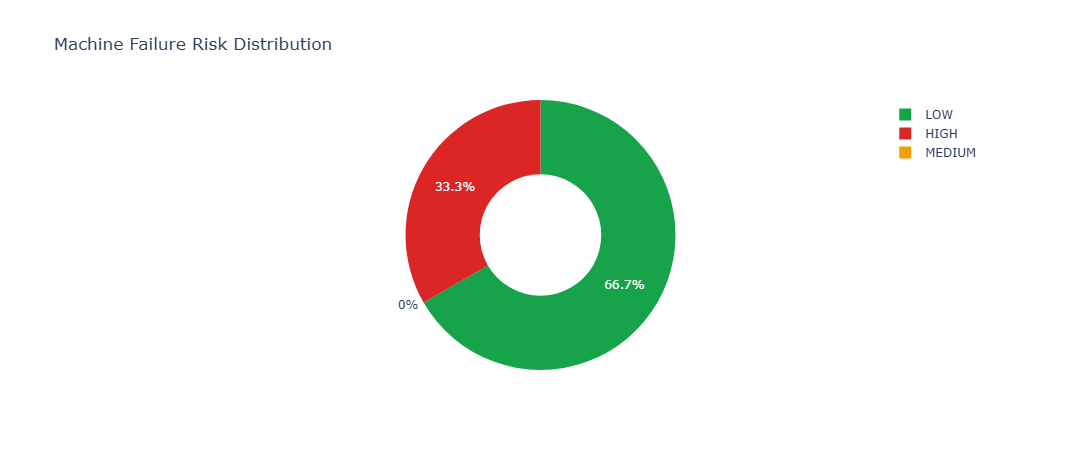

In [46]:
risk_data = dashboard_data["risk_distribution"]

risk_df = pd.DataFrame({
    "Risk Level": list(risk_data.keys()),
    "Count": list(risk_data.values())
})

fig = px.pie(
    risk_df,
    names="Risk Level",
    values="Count",
    title="Machine Failure Risk Distribution",
    hole=0.45,
    color="Risk Level",
    color_discrete_map={
        "LOW": "#16a34a",
        "MEDIUM": "#f59e0b",
        "HIGH": "#dc2626"
    }
)

fig.update_layout(
    template="plotly_white",
    height=450
)

fig.show()

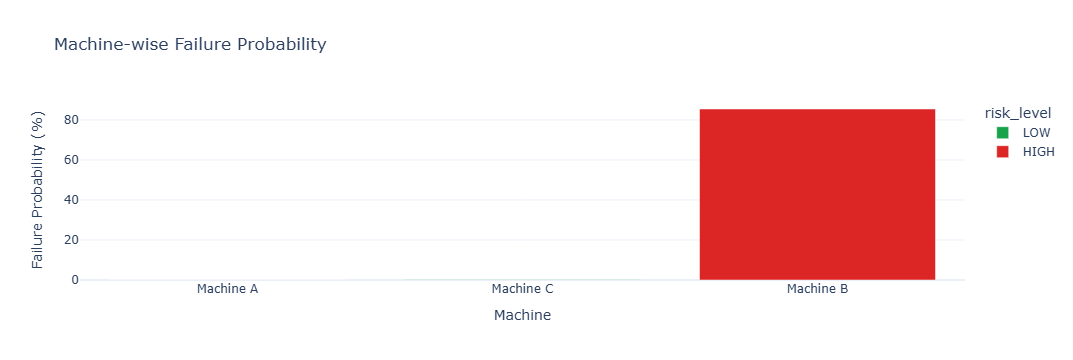

In [47]:
connection = sqlite3.connect(DB_PATH)

history_df = pd.read_sql_query("""
    SELECT
        m.machine_name,
        p.failure_probability,
        p.risk_level,
        p.predicted_at
    FROM predictions p
    JOIN machines m
    ON p.machine_id = m.machine_id
    ORDER BY p.prediction_id
""", connection)

connection.close()

fig = px.bar(
    history_df,
    x="machine_name",
    y="failure_probability",
    color="risk_level",
    title="Machine-wise Failure Probability",
    labels={
        "machine_name": "Machine",
        "failure_probability": "Failure Probability (%)"
    },
    color_discrete_map={
        "LOW": "#16a34a",
        "MEDIUM": "#f59e0b",
        "HIGH": "#dc2626"
    }
)

fig.update_layout(template="plotly_white")

fig.show()

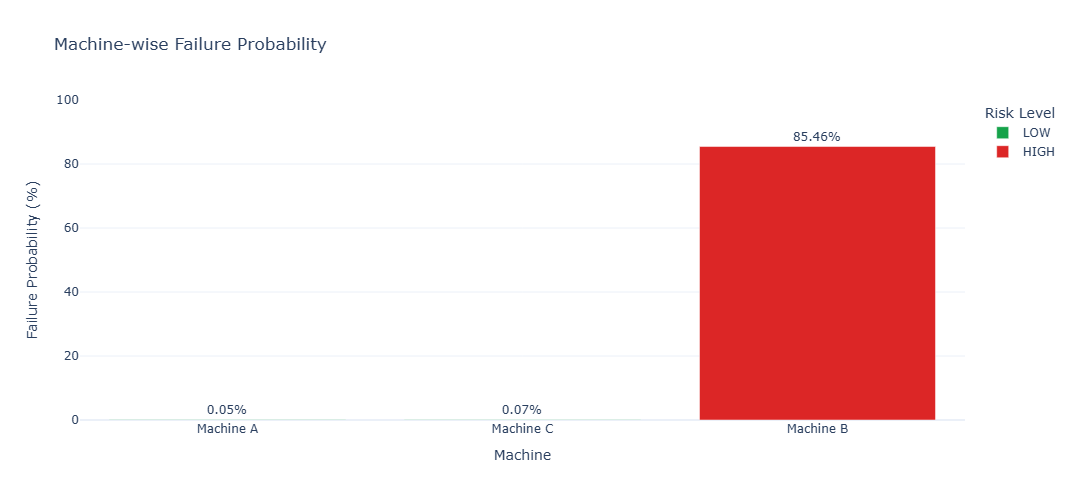

In [48]:
fig = px.bar(
    history_df,
    x="machine_name",
    y="failure_probability",
    color="risk_level",
    text=history_df["failure_probability"].apply(
        lambda x: f"{x:.2f}%"
    ),
    title="Machine-wise Failure Probability",
    labels={
        "machine_name": "Machine",
        "failure_probability": "Failure Probability (%)",
        "risk_level": "Risk Level"
    },
    color_discrete_map={
        "LOW": "#16a34a",
        "MEDIUM": "#f59e0b",
        "HIGH": "#dc2626"
    }
)

fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    template="plotly_white",
    height=500,
    yaxis=dict(
        title="Failure Probability (%)",
        range=[0, 100]
    )
)

fig.show()

In [49]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [50]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import requests

In [51]:
machine_name_input = widgets.Text(
    description="Machine Name:",
    placeholder="Enter machine name",
    value="Machine D"
)

machine_type_input = widgets.Dropdown(
    options=["L", "M", "H"],
    description="Machine Type:"
)

air_temp_input = widgets.FloatText(
    value=300.1,
    description="Air Temp (K):"
)

process_temp_input = widgets.FloatText(
    value=310.2,
    description="Process Temp (K):"
)

rpm_input = widgets.IntText(
    value=1500,
    description="Speed (RPM):"
)

torque_input = widgets.FloatText(
    value=40,
    description="Torque (Nm):"
)

tool_wear_input = widgets.IntText(
    value=120,
    description="Tool Wear:"
)

predict_button = widgets.Button(
    description="Predict Machine Failure",
    button_style="primary",
    icon="search"
)

output = widgets.Output()

In [52]:
def on_predict_clicked(b):

    with output:
        clear_output()

        payload = {
            "machine_name": machine_name_input.value,
            "machine_type": machine_type_input.value,
            "air_temperature": air_temp_input.value,
            "process_temperature": process_temp_input.value,
            "rotational_speed": rpm_input.value,
            "torque": torque_input.value,
            "tool_wear": tool_wear_input.value
        }

        response = client.post(
            "/api/predict",
            json=payload
        )

        print("HTTP Status:", response.status_code)

        result = response.get_json()

        if response.status_code == 200:

            print("\nMACHINE HEALTH REPORT")
            print("---------------------")

            print("Machine:", result["machine_name"])
            print("Failure Probability:",
                  result["failure_probability"], "%")
            print("Status:", result["machine_status"])
            print("Risk Level:", result["risk_level"])

            print("\nMaintenance Recommendations:")

            for recommendation in result["recommendations"]:
                print("-", recommendation)

        else:
            print("Error:", result)


predict_button.on_click(on_predict_clicked)

In [53]:
form = widgets.VBox([
    widgets.HTML("<h2>Predictive Maintenance System</h2>"),
    machine_name_input,
    machine_type_input,
    air_temp_input,
    process_temp_input,
    rpm_input,
    torque_input,
    tool_wear_input,
    predict_button,
    output
])

display(form)

In [54]:
connection = sqlite3.connect(DB_PATH)

monitoring_df = pd.read_sql_query("""
    SELECT
        m.machine_id,
        m.machine_name,
        m.machine_type,
        p.failure_probability,
        p.machine_status,
        p.risk_level,
        p.predicted_at

    FROM machines m

    LEFT JOIN predictions p
        ON p.prediction_id = (
            SELECT MAX(p2.prediction_id)
            FROM predictions p2
            WHERE p2.machine_id = m.machine_id
        )

    ORDER BY m.machine_id
""", connection)

connection.close()

monitoring_df["failure_probability"] = (
    monitoring_df["failure_probability"].round(2)
)

display(monitoring_df)

,machine_id,machine_name,machine_type,failure_probability,machine_status,risk_level,predicted_at
0,1,Machine A,L,0.05,NORMAL,LOW,2026-11-09 11:10:35
1,2,Machine B,M,85.46,FAILURE RISK,HIGH,2026-11-09 11:10:36
2,3,Machine C,H,0.07,NORMAL,LOW,2026-11-09 11:23:14


In [55]:
def highlight_risk(row):

    if row["risk_level"] == "HIGH":
        return ["background-color: #fee2e2"] * len(row)

    elif row["risk_level"] == "MEDIUM":
        return ["background-color: #fef3c7"] * len(row)

    elif row["risk_level"] == "LOW":
        return ["background-color: #dcfce7"] * len(row)

    return [""] * len(row)


display(
    monitoring_df.style
    .apply(highlight_risk, axis=1)
    .format({
        "failure_probability": "{:.2f}%"
    })
)

,machine_id,machine_name,machine_type,failure_probability,machine_status,risk_level,predicted_at
0,1,Machine A,L,0.05%,NORMAL,LOW,2026-11-09 11:10:35
1,2,Machine B,M,85.46%,FAILURE RISK,HIGH,2026-11-09 11:10:36
2,3,Machine C,H,0.07%,NORMAL,LOW,2026-11-09 11:23:14


In [56]:
connection = sqlite3.connect(DB_PATH)

maintenance_df = pd.read_sql_query("""
    SELECT
        p.prediction_id,
        m.machine_name,
        p.failure_probability,
        p.risk_level,
        p.recommendations,
        p.predicted_at

    FROM predictions p

    JOIN machines m
        ON p.machine_id = m.machine_id

    ORDER BY p.prediction_id DESC
""", connection)

connection.close()

display(maintenance_df)

,prediction_id,machine_name,failure_probability,risk_level,recommendations,predicted_at
0,3,Machine C,0.07,LOW,Low failure risk: Continue routine monitoring.,2026-11-09 11:23:14
1,2,Machine B,85.46,HIGH,High failure risk: Arrange prompt machine insp...,2026-11-09 11:10:36
2,1,Machine A,0.05,LOW,Low failure risk: Continue routine monitoring.,2026-11-09 11:10:35


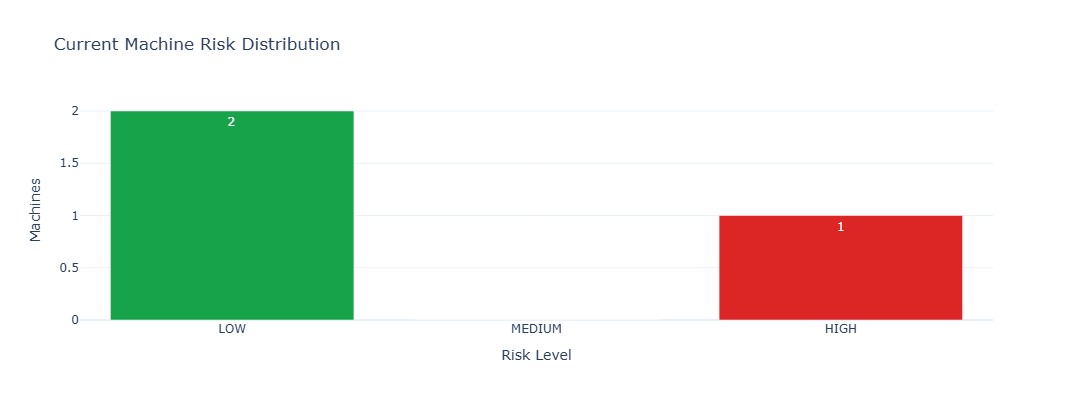

In [57]:
risk_counts = (
    monitoring_df["risk_level"]
    .value_counts()
    .reindex(["LOW", "MEDIUM", "HIGH"], fill_value=0)
    .reset_index()
)

risk_counts.columns = ["Risk Level", "Machines"]

fig = px.bar(
    risk_counts,
    x="Risk Level",
    y="Machines",
    color="Risk Level",
    text="Machines",
    title="Current Machine Risk Distribution",
    color_discrete_map={
        "LOW": "#16a34a",
        "MEDIUM": "#f59e0b",
        "HIGH": "#dc2626"
    }
)

fig.update_layout(
    template="plotly_white",
    height=400,
    showlegend=False
)

fig.show()

In [58]:
from IPython.display import display, HTML

# Refresh live dashboard statistics
response = client.get("/api/dashboard/stats")
stats = response.get_json()

# Refresh latest machine monitoring data
connection = sqlite3.connect(DB_PATH)

monitoring_df = pd.read_sql_query("""
    SELECT
        m.machine_id,
        m.machine_name,
        m.machine_type,
        p.failure_probability,
        p.machine_status,
        p.risk_level,
        p.predicted_at
    FROM machines m
    LEFT JOIN predictions p
    ON p.prediction_id = (
        SELECT MAX(p2.prediction_id)
        FROM predictions p2
        WHERE p2.machine_id = m.machine_id
    )
    ORDER BY m.machine_id
""", connection)

maintenance_df = pd.read_sql_query("""
    SELECT
        m.machine_name,
        p.failure_probability,
        p.risk_level,
        p.recommendations,
        p.predicted_at
    FROM predictions p
    JOIN machines m ON p.machine_id = m.machine_id
    ORDER BY p.prediction_id DESC
""", connection)

connection.close()

# Dashboard header and KPI cards
html = f"""
<div style="font-family:Arial;background:#f4f6fa;padding:25px;border-radius:12px">

<h1 style="color:#17365D">
Predictive Maintenance Intelligence
</h1>

<p>Equipment Health Monitoring Dashboard</p>

<div style="display:flex;gap:15px;flex-wrap:wrap">

<div style="background:white;padding:20px;border-radius:10px;flex:1">
<h4>Total Machines</h4>
<h1>{stats['total_machines']}</h1>
</div>

<div style="background:white;padding:20px;border-radius:10px;flex:1">
<h4>Total Predictions</h4>
<h1>{stats['total_predictions']}</h1>
</div>

<div style="background:white;padding:20px;border-radius:10px;flex:1">
<h4>Failure Alerts</h4>
<h1 style="color:#dc2626">{stats['failure_alerts']}</h1>
</div>

<div style="background:white;padding:20px;border-radius:10px;flex:1">
<h4>Sensor Readings</h4>
<h1>{stats['total_sensor_readings']}</h1>
</div>

</div>
</div>
"""

display(HTML(html))

# Machine monitoring
print("MACHINE MONITORING")
display(monitoring_df)

# Maintenance history
print("MAINTENANCE HISTORY")
display(maintenance_df)

MACHINE MONITORING


,machine_id,machine_name,machine_type,failure_probability,machine_status,risk_level,predicted_at
0,1,Machine A,L,0.05,NORMAL,LOW,2026-11-09 11:10:35
1,2,Machine B,M,85.46,FAILURE RISK,HIGH,2026-11-09 11:10:36
2,3,Machine C,H,0.07,NORMAL,LOW,2026-11-09 11:23:14


MAINTENANCE HISTORY


,machine_name,failure_probability,risk_level,recommendations,predicted_at
0,Machine C,0.07,LOW,Low failure risk: Continue routine monitoring.,2026-11-09 11:23:14
1,Machine B,85.46,HIGH,High failure risk: Arrange prompt machine insp...,2026-11-09 11:10:36
2,Machine A,0.05,LOW,Low failure risk: Continue routine monitoring.,2026-11-09 11:10:35
